### Libraries

In [1]:
import torch
import pandas as pd
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from tqdm.auto import tqdm

/home/matteo/Documents/Projects/DemocraSci-AM/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
print(f"Using device: {device}")

Using device: cpu


# Speech and Topic

We have a topic assigned to each paragraph from the clustering step.

Given that each paragraph can have multiple sentences, we can split the paragraph into sentences and perform NLI on each sentence against the topic. This way, we can capture more fine-grained stances within a paragraph.

Why not performing clustering on sentences instead of paragraphs? 
- Because we want to maintain the context of the paragraph, which can be important for understanding the stance. Clustering on sentences might lead to losing this context and could result in less coherent topics.

In [3]:
df = pd.read_json("speeches_with_topics.jsonl", lines=True)
df

,Speech_ID,Paragraph_ID,TEXT_SPAN,role,language_of_text,name,Topic,Name,Representation,Representative_Docs,Top_n_words,Representative_document
0,81895,81895_p1,Aber es geht hier noch um andere Fragen. Es ge...,Member of the federal council,DE,Schmid Samuel,108,"108_National Security, Armed Forces, Defense","[National Security, Armed Forces, Defense]",[Der Bundesrat hat zudem am 21. September 2012...,"National Security, Armed Forces, Defense",False
1,81895,81895_p2,"Verschiedene andere Fragen, beispielsweise jen...",Member of the federal council,DE,Schmid Samuel,108,"108_National Security, Armed Forces, Defense","[National Security, Armed Forces, Defense]",[Der Bundesrat hat zudem am 21. September 2012...,"National Security, Armed Forces, Defense",False
2,81895,81895_p3,"Also sind wir bereit, die Analysen zu machen, ...",Member of the federal council,DE,Schmid Samuel,108,"108_National Security, Armed Forces, Defense","[National Security, Armed Forces, Defense]",[Der Bundesrat hat zudem am 21. September 2012...,"National Security, Armed Forces, Defense",False
3,83146,83146_p2,Zum Antrag der Minderheit Maury Pasquier: Dies...,For the committee,DE,Schwaller Urs,67,67_Health insurance costs,[Health insurance costs],[Zu den Anträgen im ersten Block: Bei Artikel ...,Health insurance costs,False
4,83146,83146_p3,Noch eine abschliessende Bemerkung: Wir streic...,For the committee,DE,Schwaller Urs,67,67_Health insurance costs,[Health insurance costs],[Zu den Anträgen im ersten Block: Bei Artikel ...,Health insurance costs,False
...,...,...,...,...,...,...,...,...,...,...,...,...
210223,288681,288681_p8,"En sus, la commission a adopté, par 13 voix co...",For the committee,FR,Python Valentine,149,149_Agriculture and Pesticides,[Agriculture and Pesticides],[Vous avez vu que le Conseil fédéral propose d...,Agriculture and Pesticides,False
210224,288681,288681_p9,Considérant le risque important de contaminati...,For the committee,FR,Python Valentine,68,68_Tobacco and alcohol regulation,[Tobacco and alcohol regulation],[La présente motion du Conseil des Etats conce...,Tobacco and alcohol regulation,False
210225,288681,288681_p11,"En commission, une minorité avait, quant à ell...",For the committee,FR,Python Valentine,68,68_Tobacco and alcohol regulation,[Tobacco and alcohol regulation],[La présente motion du Conseil des Etats conce...,Tobacco and alcohol regulation,False
210226,288681,288681_p12,La proposition individuelle Bäumle déposée hie...,For the committee,FR,Python Valentine,149,149_Agriculture and Pesticides,[Agriculture and Pesticides],[Vous avez vu que le Conseil fédéral propose d...,Agriculture and Pesticides,False


In [4]:
df[["Topic", "Name", "Representation"]].explode(
    "Representation"
).drop_duplicates().reset_index(drop=True).to_csv("unique_topics.csv", index=False)

In [5]:
df_revised = pd.read_csv("unique_topics_withDirections.csv")

In [6]:
merged_df = pd.merge(
    df.drop(columns=["Name", "Representation"]),
    df_revised,
    on="Topic",
    how="left",
)

In [7]:
merged_df.head()

,Speech_ID,Paragraph_ID,TEXT_SPAN,role,language_of_text,name,Topic,Representative_Docs,Top_n_words,Representative_document,Name,Representation,Representation_with_Direction,Alternatives (stronger in tone)
0,81895,81895_p1,Aber es geht hier noch um andere Fragen. Es ge...,Member of the federal council,DE,Schmid Samuel,108,[Der Bundesrat hat zudem am 21. September 2012...,"National Security, Armed Forces, Defense",False,"108_National Security, Armed Forces, Defense","National Security, Armed Forces, Defense","Expanding national security, armed forces and ...",NaN
1,81895,81895_p2,"Verschiedene andere Fragen, beispielsweise jen...",Member of the federal council,DE,Schmid Samuel,108,[Der Bundesrat hat zudem am 21. September 2012...,"National Security, Armed Forces, Defense",False,"108_National Security, Armed Forces, Defense","National Security, Armed Forces, Defense","Expanding national security, armed forces and ...",NaN
2,81895,81895_p3,"Also sind wir bereit, die Analysen zu machen, ...",Member of the federal council,DE,Schmid Samuel,108,[Der Bundesrat hat zudem am 21. September 2012...,"National Security, Armed Forces, Defense",False,"108_National Security, Armed Forces, Defense","National Security, Armed Forces, Defense","Expanding national security, armed forces and ...",NaN
3,83146,83146_p2,Zum Antrag der Minderheit Maury Pasquier: Dies...,For the committee,DE,Schwaller Urs,67,[Zu den Anträgen im ersten Block: Bei Artikel ...,Health insurance costs,False,67_Health insurance costs,Health insurance costs,Reducing health insurance costs,NaN
4,83146,83146_p3,Noch eine abschliessende Bemerkung: Wir streic...,For the committee,DE,Schwaller Urs,67,[Zu den Anträgen im ersten Block: Bei Artikel ...,Health insurance costs,False,67_Health insurance costs,Health insurance costs,Reducing health insurance costs,NaN


In [ ]:
merged_df[
    merged_df["Representation_with_Direction"]
    == "Expanding ethics requirements for human research"
]["TEXT_SPAN"].to_csv("text_span.csv")

# Hypothesis Template

In [11]:
hp_df = merged_df.copy()

In [12]:
PRO_TEMPLATE = "The speaker advocates in favor of {}."
CON_TEMPLATE = "The speaker advocates against {}."

In [13]:
hp_df["hypo_pro"] = hp_df["Representation_with_Direction"].apply(
    lambda x: PRO_TEMPLATE.format(x)
)
hp_df["hypo_con"] = hp_df["Representation_with_Direction"].apply(
    lambda x: CON_TEMPLATE.format(x)
)

# NLI Model

In [ ]:
model_name = "MoritzLaurer/DeBERTa-v3-large-mnli-fever-anli-ling-wanli"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(
    model_name, torch_dtype="auto"
).to(device)

Loading weights: 100% 394/394 [00:00<00:00, 4558.42it/s]


In [37]:
import numpy as np

BATCH_SIZE = 64
n_rows = len(hp_df)
model.eval()

support_scores = np.zeros(n_rows)
oppose_scores = np.zeros(n_rows)

In [38]:
for i in tqdm(range(0, n_rows, BATCH_SIZE)):
    batch = hp_df.iloc[i : i + BATCH_SIZE]

    batch_premises = []
    batch_hypotheses = []
    for _, row in batch.iterrows():
        batch_premises.extend([row["TEXT_SPAN"], row["TEXT_SPAN"]])
        batch_hypotheses.extend([row["hypo_pro"], row["hypo_con"]])

    inputs = tokenizer(
        batch_premises,
        batch_hypotheses,
        truncation="only_first",
        padding=True,
        return_tensors="pt",
    ).to(device)

    with torch.no_grad():
        outputs = model(**inputs)
        probs = torch.softmax(outputs.logits, dim=-1)[:, 0].cpu().numpy()

    support_scores[i : i + BATCH_SIZE] = probs[0::2]
    oppose_scores[i : i + BATCH_SIZE] = probs[1::2]

100% 3285/3285 [44:47<00:00,  1.22it/s]


In [39]:
hp_df["P_pro"] = support_scores
hp_df["P_con"] = oppose_scores

hp_df["Stance_Intensity"] = hp_df["P_pro"] - hp_df["P_con"]

In [ ]:
hp_df.to_csv("speeches_with_nli.csv")

In [2]:
import pandas as pd

hp_df = pd.read_csv("speeches_with_nli.csv", index_col=0)

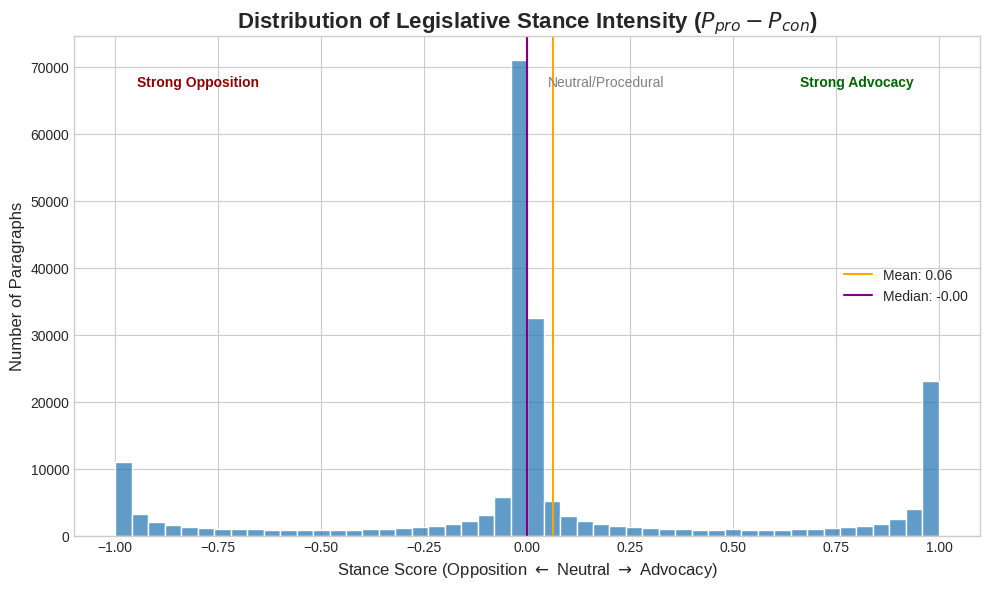

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(
    hp_df["Stance_Intensity"],
    bins=50,
    color="#2c7bb6",
    edgecolor="white",
)
# Customize axes
ax.set_title(
    "Distribution of Legislative Stance Intensity ($P_{pro} - P_{con}$)",
    fontsize=16,
    fontweight="bold",
)
ax.set_xlabel(
    r"Stance Score (Opposition $\leftarrow$ Neutral $\rightarrow$ Advocacy)",
    fontsize=12,
)
ax.set_ylabel("Number of Paragraphs", fontsize=12)

plt.axvline(x=0, color="red", linestyle="--", alpha=0.6)
plt.text(
    -0.8,
    ax.get_ylim()[1] * 0.9,
    "Strong Opposition",
    color="darkred",
    fontweight="bold",
    ha="center",
)
plt.text(
    0.8,
    ax.get_ylim()[1] * 0.9,
    "Strong Advocacy",
    color="darkgreen",
    fontweight="bold",
    ha="center",
)
plt.text(0.05, ax.get_ylim()[1] * 0.9, "Neutral/Procedural", color="gray", ha="left")

# Add mean and median info
plt.axvline(
    x=hp_df["Stance_Intensity"].mean(),
    color="orange",
    label=f"Mean: {hp_df['Stance_Intensity'].mean():.2f}",
)
plt.axvline(
    x=hp_df["Stance_Intensity"].median(),
    color="purple",
    label=f"Median: {hp_df['Stance_Intensity'].median():.2f}",
)

plt.legend()
plt.tight_layout()
plt.show()

In [5]:
hp_df[hp_df["Stance_Intensity"] > 0.75].head()

,Speech_ID,Paragraph_ID,TEXT_SPAN,role,language_of_text,name,Topic,Representative_Docs,Top_n_words,Representative_document,Name,Representation,Representation_with_Direction,Alternatives (stronger in tone),hypo_pro,hypo_con,P_pro,P_con,Stance_Intensity
1,81895,81895_p2,"Verschiedene andere Fragen, beispielsweise jen...",Member of the federal council,DE,Schmid Samuel,108,['Der Bundesrat hat zudem am 21. September 201...,"National Security, Armed Forces, Defense",False,"108_National Security, Armed Forces, Defense","National Security, Armed Forces, Defense","Expanding national security, armed forces and ...",NaN,The speaker advocates in favor of Expanding na...,The speaker advocates against Expanding nation...,0.839355,0.000377,0.838978
14,81900,81900_p2,Die unterlegenen Befürworter der Initiative st...,For the committee,DE,Widmer Hans,108,['Der Bundesrat hat zudem am 21. September 201...,"National Security, Armed Forces, Defense",False,"108_National Security, Armed Forces, Defense","National Security, Armed Forces, Defense","Expanding national security, armed forces and ...",NaN,The speaker advocates in favor of Expanding na...,The speaker advocates against Expanding nation...,0.992188,0.000240,0.991947
17,81905,81905_p0,Le présent accord concerne la collaboration en...,For the committee,FR,Veillon Pierre-François,130,"[""Après ce contexte multipolaire, la deuxième ...",International Security and Human Rights,False,130_International Security and Human Rights,International Security and Human Rights,Improving international security and human rights,Prioritising international security commitment...,The speaker advocates in favor of Improving in...,The speaker advocates against Improving intern...,0.982422,0.001122,0.981299
22,83153,83153_p1,"Sur le fond, nous sommes d'accord avec l'auteu...",President of the federal council,FR,Couchepin Pascal,77,"[""Ce besoin de réagir dans l'urgence se retrou...",Swiss research and innovation,False,77_Swiss research and innovation,Swiss research and innovation,Expanding Swiss research and innovation,NaN,The speaker advocates in favor of Expanding Sw...,The speaker advocates against Expanding Swiss ...,0.981934,0.000364,0.981570
34,81911,81911_p3,"1. die Schaffung einer Verfassungsgrundlage, w...",For the committee,DE,Gysin Hans Rudolf,51,['Ich möchte Ihnen vorgängig nochmals die Spie...,Federal Guarantee of Cantonal Constitutions,False,51_Federal Guarantee of Cantonal Constitutions,Federal Guarantee of Cantonal Constitutions,Federal Guarantee of Cantonal Constitutions,NaN,The speaker advocates in favor of Federal Guar...,The speaker advocates against Federal Guarante...,0.863281,0.015388,0.847893


In [6]:
hp_df[hp_df["Stance_Intensity"] < -0.75].head()

,Speech_ID,Paragraph_ID,TEXT_SPAN,role,language_of_text,name,Topic,Representative_Docs,Top_n_words,Representative_document,Name,Representation,Representation_with_Direction,Alternatives (stronger in tone),hypo_pro,hypo_con,P_pro,P_con,Stance_Intensity
3,83146,83146_p2,Zum Antrag der Minderheit Maury Pasquier: Dies...,For the committee,DE,Schwaller Urs,67,['Zu den Anträgen im ersten Block: Bei Artikel...,Health insurance costs,False,67_Health insurance costs,Health insurance costs,Reducing health insurance costs,NaN,The speaker advocates in favor of Reducing hea...,The speaker advocates against Reducing health ...,0.000772,0.992676,-0.991904
6,83146,83146_p5,Weiter mischen sich die Kantone nun auch in de...,For the committee,DE,Schwaller Urs,50,"['Herr Flach, die Fragen, die Sie ansprechen, ...",Federalism and cantonal relations,False,50_Federalism and cantonal relations,Federalism and cantonal relations,Strengthening cantonal autonomy at the expense...,NaN,The speaker advocates in favor of Strengthenin...,The speaker advocates against Strengthening ca...,0.000344,0.998535,-0.998191
12,83147,83147_p5,On vient de me transmettre la lettre de la Con...,President of the federal council,FR,Couchepin Pascal,85,"[""Le rapporteur de la commission a mentionné q...",Federal-Cantonal Relations,False,85_Federal-Cantonal Relations,Federal-Cantonal Relations,Strengthening cantonal autonomy at the expense...,NaN,The speaker advocates in favor of Strengthenin...,The speaker advocates against Strengthening ca...,0.001891,0.983887,-0.981996
13,83149,83149_p1,"Monsieur le président de la Confédération, il ...",For the committee,DE,Schwaller Urs,85,"[""Le rapporteur de la commission a mentionné q...",Federal-Cantonal Relations,False,85_Federal-Cantonal Relations,Federal-Cantonal Relations,Strengthening cantonal autonomy at the expense...,NaN,The speaker advocates in favor of Strengthenin...,The speaker advocates against Strengthening ca...,0.039093,0.945312,-0.906219
15,81900,81900_p3,Das schliesslich obsiegende Nein war durch fol...,For the committee,DE,Widmer Hans,108,['Der Bundesrat hat zudem am 21. September 201...,"National Security, Armed Forces, Defense",False,"108_National Security, Armed Forces, Defense","National Security, Armed Forces, Defense","Expanding national security, armed forces and ...",NaN,The speaker advocates in favor of Expanding na...,The speaker advocates against Expanding nation...,0.000240,0.996582,-0.996342


In [7]:
mp_metadata = pd.read_csv("mp_metadata.csv")
mp_metadata.head()

,uid,first_name,last_name,fullname,gender,party,party_name
0,1354,Alois,Ab Yberg,Ab Yberg Alois,m,FDP-Liberale,FDP.Die Liberalen
1,801,Fabio,Abate,Abate Fabio,m,FDP-Liberale,FDP.Die Liberalen
2,1355,Alfred,Abegg,Abegg Alfred,m,SP,Sozialdemokratische Partei der Schweiz
3,1356,Johann Jakob,Abegg,Abegg Johann Jakob,m,LDP,Liberale Demokratische Partei
4,1357,H. Roman,Abt,Abt H. Roman,m,SVP,Schweizerische Volkspartei


In [8]:
result_with_party = hp_df.merge(
    mp_metadata[["fullname", "party"]], left_on="name", right_on="fullname", how="left"
)

In [9]:
missing_parties = result_with_party[result_with_party["party"].isna()]
mps_missing_parties = missing_parties["name"].unique().tolist()

In [10]:
mps_missing_parties

['Pieren Nadja',
 'Rickli Natalie Simone',
 'Roth-Bernasconi Maria',
 'Markwalder Bär Christa',
 'Humbel Näf Ruth',
 'Bruderer Pascale',
 'Haller Ursula',
 'Paganini Nicolo',
 'Rutz Gregor A.',
 'Bellaïche Judith',
 'Weichelt-Picard Manuela',
 'Walder Nicolas Michel']

In [11]:
# Fix names
correct_name_mapping = {
    "Pieren Nadja": "Umbricht Pieren Nadja",
    "Rickli Natalie Simone": "Rickli Natalie",
    "Roth-Bernasconi Maria": "Bernasconi Maria",
    "Markwalder Bär Christa": "Markwalder Christa",
    "Humbel Näf Ruth": "Humbel Ruth",
    "Bruderer Pascale": "Bruderer Wyss Pascale",
    "Haller Ursula": "Haller Vannini Ursula",
    "Paganini Nicolo": "Paganini Nicolò",
    "Rutz Gregor A.": "Rutz Gregor",
    "Bellaïche Judith": "Bellaiche Judith",
    "Weichelt-Picard Manuela": "Weichelt Manuela",
    "Walder Nicolas Michel": "Walder Nicolas",
}

In [12]:
hp_df_fixed = hp_df.copy()
hp_df_fixed["name"] = hp_df_fixed["name"].replace(correct_name_mapping)
result_with_party = hp_df_fixed.merge(
    mp_metadata[["fullname", "gender", "party", "party_name"]],
    left_on="name",
    right_on="fullname",
    how="left",
)
result_with_party.to_csv("speeches_with_nli_and_party.csv", index=False)

missing_count = result_with_party["party"].isna().sum()
print(f"Total rows missing party assignment: {missing_count}")
if missing_count > 0:
    print(
        result_with_party[result_with_party["party"].isna()]["name"]
        .value_counts()
        .head(10)
    )

Total rows missing party assignment: 0


In [13]:
# Prioritization Index (PI)
# We use the absolute value of Stance_Intensity for 'Priority' and the raw value for 'Direction'
result_with_party["abs_intensity"] = result_with_party["Stance_Intensity"].abs()

# Group by Party and Topic
party_advocacy = (
    result_with_party.groupby(["party", "Representation_with_Direction"])
    .agg(
        avg_stance=("Stance_Intensity", "mean"),
        avg_priority=("abs_intensity", "mean"),
        speech_count=("TEXT_SPAN", "count"),
    )
    .reset_index()
)

# Advocacy Index
# PI = How often they talk about it * How strongly they feel
party_advocacy["advocacy_index"] = (
    party_advocacy["speech_count"] * party_advocacy["avg_stance"]
)

# View the Top Advocacy for a specific party (e.g., SVP)
party_advocacy[party_advocacy["party"] == "SVP"].sort_values(
    by="advocacy_index", ascending=False
).head(10)

,party,Representation_with_Direction,avg_stance,avg_priority,speech_count,advocacy_index
1152,SVP,"Expanding national security, armed forces and ...",0.224976,0.521902,2065,464.575007
1225,SVP,Strengthening Swiss engagement in internationa...,0.283031,0.421160,1133,320.674076
1233,SVP,Strengthening data protection and privacy rights,0.216764,0.401762,1031,223.484069
1211,SVP,Reforming social security to ensure long-term ...,0.227035,0.331391,825,187.303980
1153,SVP,Expanding prevention measures against terrorism,0.428194,0.511396,313,134.024876
1204,SVP,Reducing health insurance costs,0.087704,0.276837,1176,103.139716
1166,SVP,Improving international security and human rights,0.260321,0.297120,396,103.086968
1140,SVP,Expanding Swiss research and innovation,0.251035,0.319415,401,100.664843
1164,SVP,Improving Swiss-EU relations,0.268960,0.388363,332,89.294879
1141,SVP,Expanding Switzerland's bilateral trade agreem...,0.286522,0.422076,302,86.529765


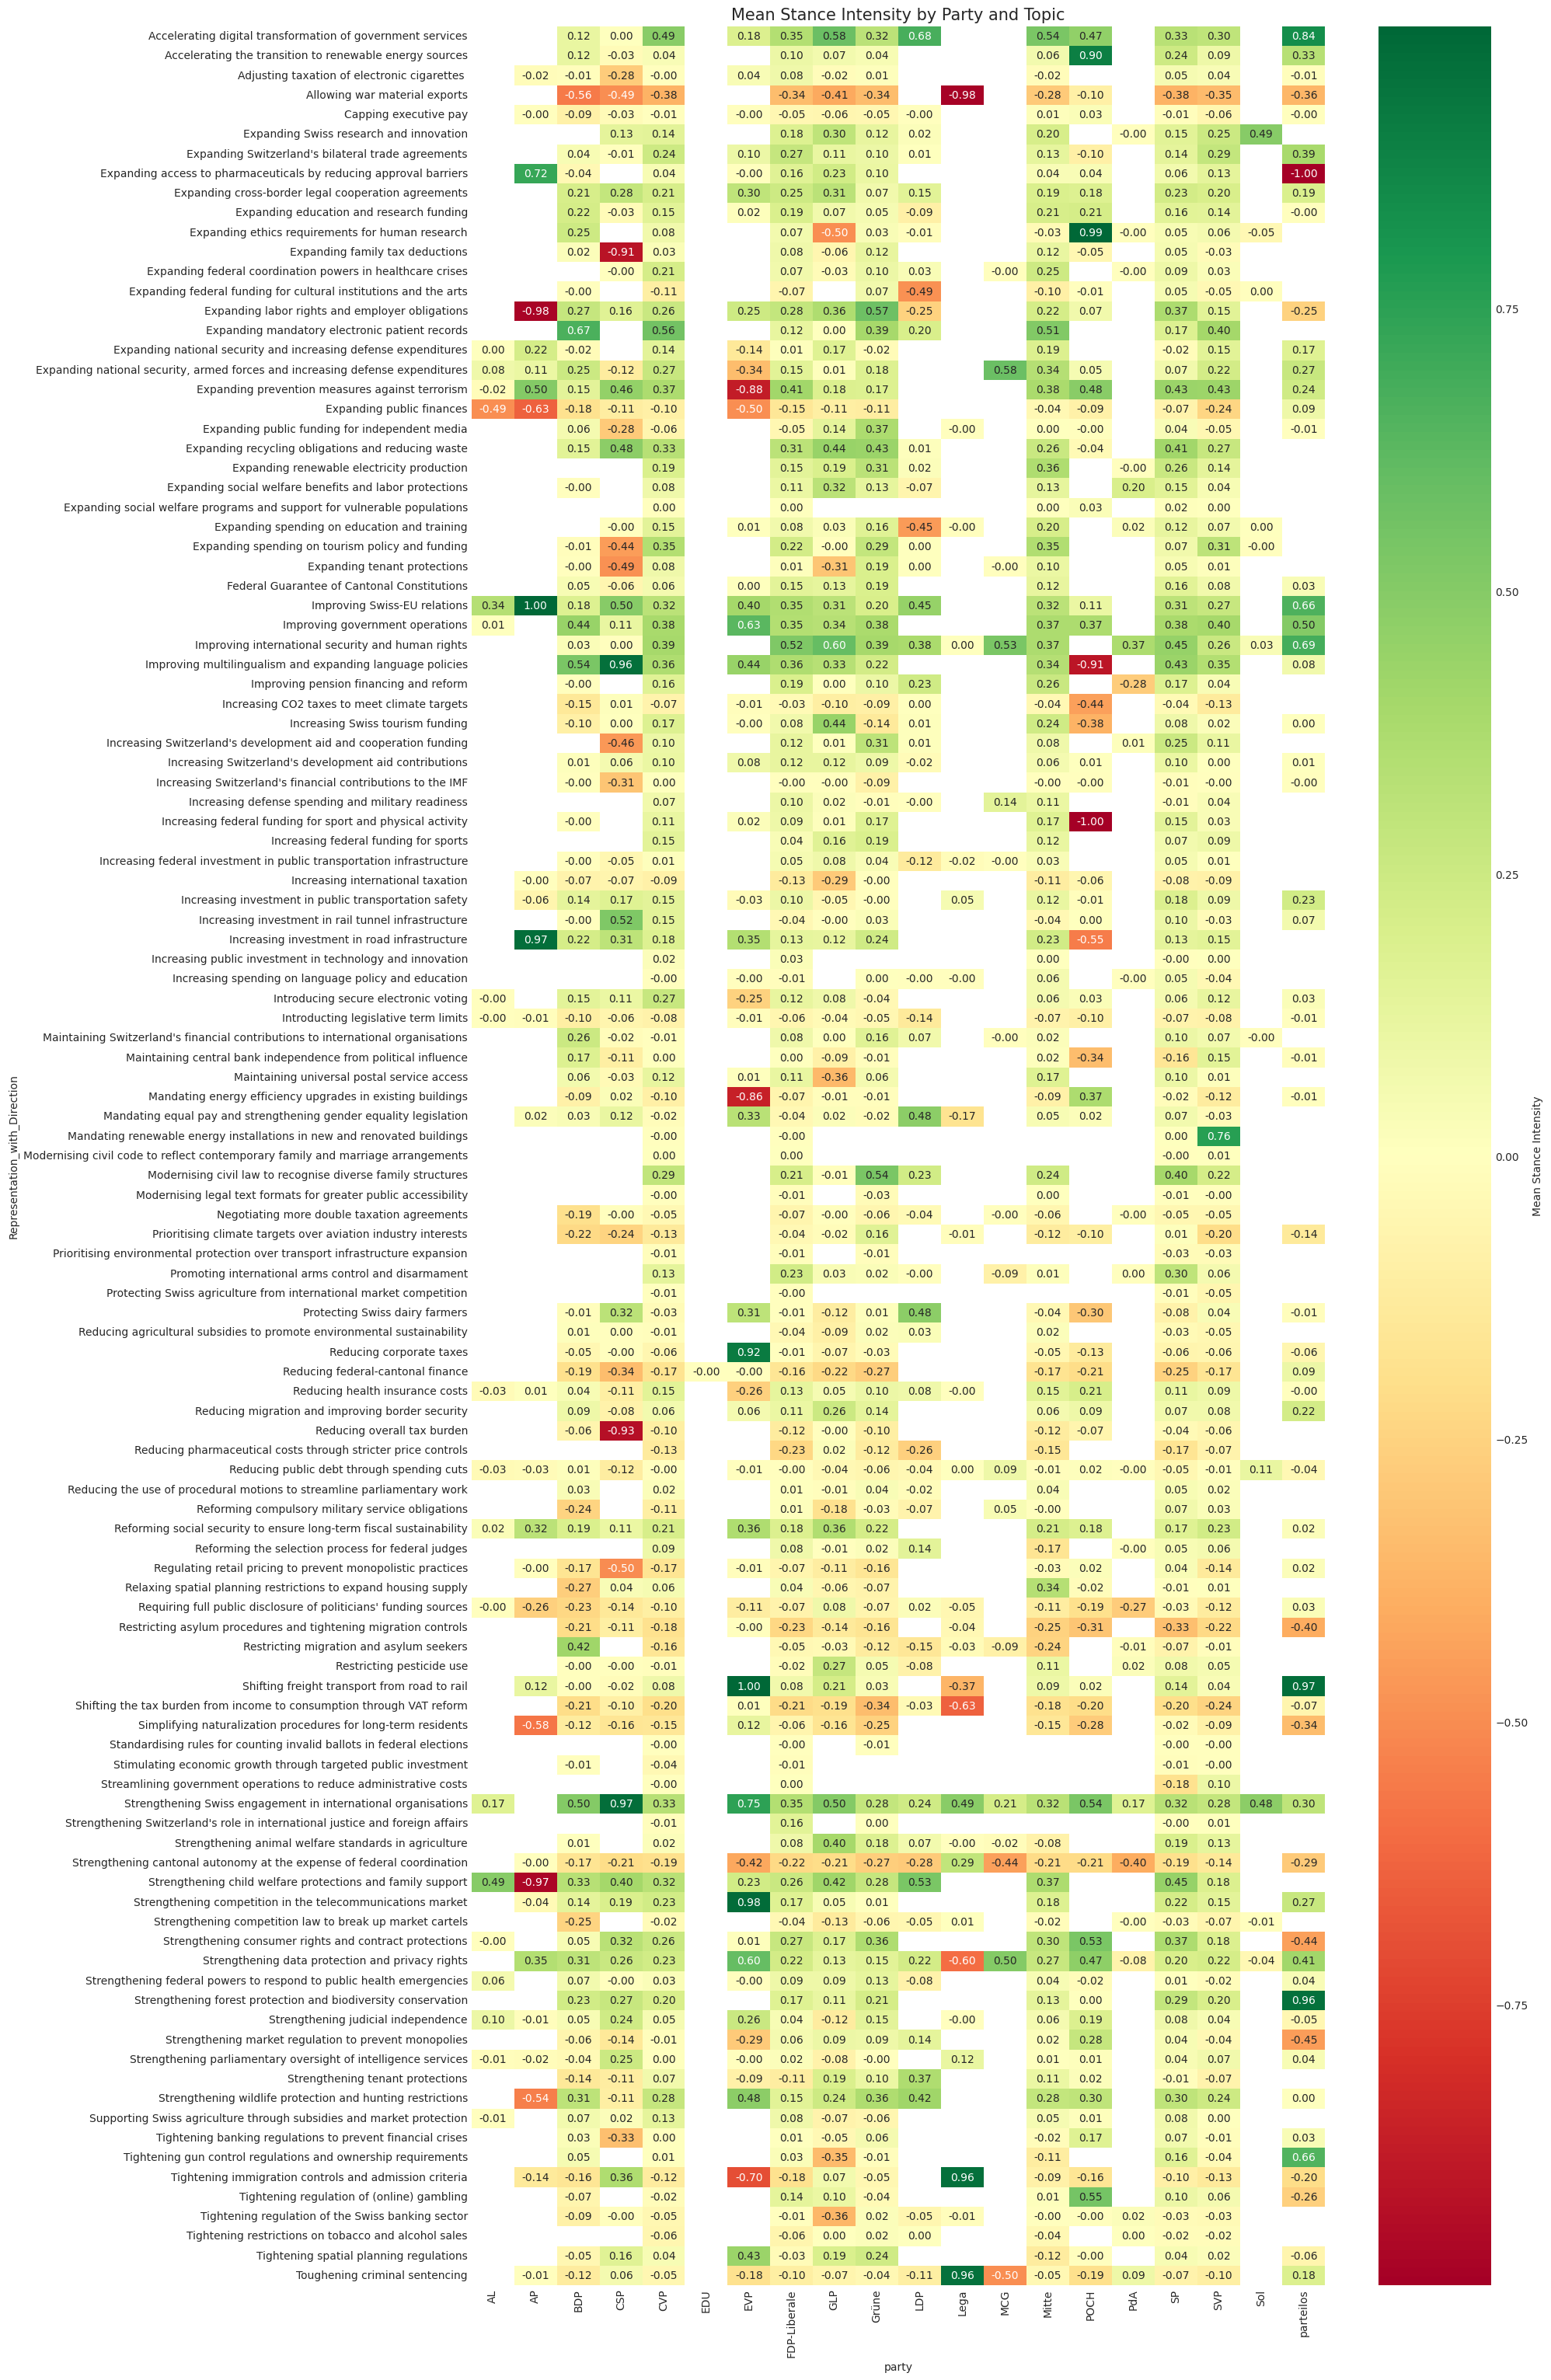

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

top_topics = result_with_party["Representation_with_Direction"].value_counts().index
pivot_df = party_advocacy[
    party_advocacy["Representation_with_Direction"].isin(top_topics)
].pivot(index="party", columns="Representation_with_Direction", values="avg_stance")

plt.figure(figsize=(20, 30))
sns.heatmap(
    pivot_df.T,
    annot=True,
    cmap="RdYlGn",
    center=0,
    cbar_kws={"label": "Mean Stance Intensity"},
    fmt=".2f",
)
plt.title(f"Mean Stance Intensity by Party and Topic", fontsize=15)
plt.grid(False)
plt.tight_layout()
plt.xticks(rotation=90)
plt.savefig("party_stance_heatmap.pdf")
plt.show()

In [ ]:
pivot_df.to_csv("pivot_party.csv", index=False)